# Stock Performance Prediction — Model 2: Temporal Convolutional Network (v2)

**Project:** Stock Performance Prediction (RNN)  
**Prerequisites:** `01_exploratory_data_analysis.ipynb`, `02_preprocessing.ipynb`  
**Loads from:** `data/processed/aapl_sequences.npz`, `scaler.json`, `pipeline_config.json`

This notebook trains and evaluates a **Temporal Convolutional Network (TCN)** classifier for next-day direction prediction on AAPL.

### v2 changes (fix model collapse)
- Replaced **GlobalAveragePooling** with **last-timestep** readout (recent days matter most)
- Simplified stack: **3 blocks** (d=1,2,4), 24 filters, kernel_size=2
- Reduced spatial dropout (0.05) and added conv L2 + **AdamW**
- Output bias initialised to training class prior (prevents "always UP" collapse)
- **Validation-tuned threshold** + prediction-std diagnostic

### Pipeline
```
Load artifacts → Build TCN → Train with early stopping
→ Tune threshold on val → Evaluate (Val + Test) → Baselines → Save model
```


## 1. Setup & Dependencies

In [1]:
import importlib.util
import os
import sys
from pathlib import Path

# Pip package name -> importable module name
REQUIRED = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scikit-learn": "sklearn",
    "tensorflow": "tensorflow",
}

missing = [
    pkg for pkg, module in REQUIRED.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    raise ImportError(
        "Missing packages in the active environment: "
        + ", ".join(missing)
        + "\nInstall with: pip install -r requirements.txt"
    )

# Prefer pip-shipped NVIDIA libs (set before importing TensorFlow).
for site_path in sys.path:
    nvidia_lib = Path(site_path) / "nvidia"
    if not nvidia_lib.is_dir():
        continue
    lib_dirs = [
        nvidia_lib / name / "lib"
        for name in ("cudnn", "cublas", "cuda_runtime", "cusolver", "cusparse", "curand", "nvjitlink", "cufft", "nccl")
        if (nvidia_lib / name / "lib").is_dir()
    ]
    if lib_dirs:
        joined = ":".join(str(p) for p in lib_dirs)
        os.environ["LD_LIBRARY_PATH"] = f"{joined}:{os.environ.get('LD_LIBRARY_PATH', '')}"
        break
wsl_lib = Path("/usr/lib/wsl/lib")
if wsl_lib.is_dir():
    os.environ["LD_LIBRARY_PATH"] = f"{wsl_lib}:{os.environ.get('LD_LIBRARY_PATH', '')}"

import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers

from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, f1_score, accuracy_score, roc_curve
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

FORCE_CPU = False


def configure_tensorflow_device(force_cpu: bool = False) -> str:
    gpus = tf.config.list_physical_devices("GPU")
    if force_cpu or not gpus:
        tf.config.set_visible_devices([], "GPU")
        return "CPU"

    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        with tf.device("/GPU:0"):
            probe = tf.keras.layers.Conv1D(8, 3, padding="causal")(
                tf.random.normal((2, 60, 16))
            )
            _ = probe.numpy()
        return f"GPU ({gpus[0].name})"
    except Exception as exc:
        tf.config.set_visible_devices([], "GPU")
        print(
            "GPU probe failed; falling back to CPU.\n"
            f"  Reason: {exc}\n"
            "  Fix: select the project .venv kernel, restart kernel, then re-run."
        )
        return "CPU"


DEVICE = configure_tensorflow_device(FORCE_CPU)

print(f"TensorFlow: {tf.__version__}")
print(f"Python:     {sys.executable}")
print(f"Device:     {DEVICE}")

I0000 00:00:1781458323.894042   94300 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1781458324.170640   94300 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1781458325.232465   94300 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1781458325.966078   94300 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute c

TensorFlow: 2.21.0
Python:     /home/friyekekanu/ai-workspace/experiments/stock-prediction/.venv/bin/python
Device:     GPU (/physical_device:GPU:0)


## 2. Load Preprocessed Artifacts

In [2]:
def find_project_root() -> Path:
    """Resolve repo root from notebooks/ or 04_ML_Model_Iteration-1/ subfolders."""
    markers = [
        Path("data/processed/aapl_sequences.npz"),
        Path("data/processed/pipeline_config.json"),
        Path("Stock Market Dataset"),
    ]
    candidates = [Path.cwd()]
    if Path.cwd().name in ("notebooks", "04_ML_Model_Iteration-1"):
        candidates.append(Path.cwd().parent)
    candidates.extend(Path.cwd().parents)
    for path in candidates:
        for marker in markers:
            if (path / marker).exists():
                return path
    raise FileNotFoundError(
        "Could not find project root. Expected data/processed/aapl_sequences.npz "
        "in an ancestor of the current working directory."
    )


PROJECT_ROOT  = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR    = PROJECT_ROOT / "data" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root:  {PROJECT_ROOT}")
print(f"Processed dir: {PROCESSED_DIR}")
print(f"Models dir:    {MODELS_DIR}")

Project root:  /home/friyekekanu/ai-workspace/experiments/stock-prediction
Processed dir: /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/processed
Models dir:    /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models


In [3]:
# ── Load sequence arrays ──────────────────────────────────────────────────
seq_path = PROCESSED_DIR / "aapl_sequences.npz"
if not seq_path.exists():
    raise FileNotFoundError(
        f"Sequences not found at {seq_path}.\n"
        "Run 02_preprocessing.ipynb first."
    )

data = np.load(seq_path, allow_pickle=True)
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]
X_test,  y_test  = data["X_test"],  data["y_test"]
feature_cols     = list(data["feature_cols"])

print("Sequence shapes loaded:")
for split, X, y in [("train", X_train, y_train),
                    ("val",   X_val,   y_val),
                    ("test",  X_test,  y_test)]:
    up_pct = y.mean() * 100
    print(f"  {split:<6}  X={X.shape}  y={y.shape}  up%={up_pct:.1f}")

print(f"\nFeatures ({len(feature_cols)}): {feature_cols}")

Sequence shapes loaded:
  train   X=(6217, 60, 7)  y=(6217,)  up%=50.5
  val     X=(503, 60, 7)  y=(503,)  up%=54.9
  test    X=(63, 60, 7)  y=(63,)  up%=42.9

Features (7): [np.str_('log_return'), np.str_('log_volume'), np.str_('intraday_range'), np.str_('volatility_21'), np.str_('return_ma_21'), np.str_('rsi_14'), np.str_('spy_log_return')]


In [4]:
# ── Load config & scaler ──────────────────────────────────────────────────
with open(PROCESSED_DIR / "pipeline_config.json") as f:
    cfg = json.load(f)

with open(PROCESSED_DIR / "scaler.json") as f:
    scaler = json.load(f)

LOOKBACK   = cfg["lookback_days"]   # 60
N_FEATURES = len(feature_cols)      # 7

print(f"Lookback: {LOOKBACK} days | Features: {N_FEATURES}")
print(f"Train end: {cfg['train_end']}  |  Val: {cfg['val_start']} – {cfg['val_end']}  |  Test: {cfg['test_start']} – {cfg['test_end']}")

Lookback: 60 days | Features: 7
Train end: 2017-12-31  |  Val: 2018-01-01 – 2019-12-31  |  Test: 2020-01-01 – 2020-04-01


## 3. Model Definition — TCN (v2)

### Architecture

Three dilated causal residual blocks (was five in v1). Each block: Conv1D → LayerNorm → ReLU → SpatialDropout × 2 + skip connection.

Dilation factors: `[1, 2, 4]` — receptive field covers the 60-day lookback without over-deepening the stack.

```
Input (60, 7)
  └─ Conv1D projection (1×1, 24 filters)
       └─ Residual block (d=1, 24)
            └─ Residual block (d=2, 24)
                 └─ Residual block (d=4, 24)
                      └─ Last timestep slice        ← replaces GlobalAvgPool
                           └─ Dense (16, ReLU) + Dropout
                                └─ Dense (1, Sigmoid)
```

**Why last timestep:** v1 GlobalAveragePooling washed out recent signal; the model collapsed to P(UP)≈0.52 for every sample.


In [5]:
def tcn_residual_block(
    x: tf.Tensor,
    filters: int,
    kernel_size: int,
    dilation_rate: int,
    dropout_rate: float,
    block_id: int,
    l2,
) -> tf.Tensor:
    residual = x

    x = layers.Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        dilation_rate=dilation_rate,
        padding="causal",
        use_bias=False,
        kernel_regularizer=l2,
        name=f"block{block_id}_conv1",
    )(x)
    x = layers.LayerNormalization(name=f"block{block_id}_ln1")(x)
    x = layers.Activation("relu", name=f"block{block_id}_relu1")(x)
    x = layers.SpatialDropout1D(dropout_rate, name=f"block{block_id}_drop1")(x)

    x = layers.Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        dilation_rate=dilation_rate,
        padding="causal",
        use_bias=False,
        kernel_regularizer=l2,
        name=f"block{block_id}_conv2",
    )(x)
    x = layers.LayerNormalization(name=f"block{block_id}_ln2")(x)
    x = layers.Activation("relu", name=f"block{block_id}_relu2")(x)
    x = layers.SpatialDropout1D(dropout_rate, name=f"block{block_id}_drop2")(x)

    if int(residual.shape[-1]) != filters:
        residual = layers.Conv1D(
            filters=filters,
            kernel_size=1,
            padding="same",
            use_bias=False,
            kernel_regularizer=l2,
            name=f"block{block_id}_skip_proj",
        )(residual)

    return layers.Add(name=f"block{block_id}_add")([x, residual])


def build_tcn(
    lookback: int,
    n_features: int,
    train_up_rate: float = 0.5,
    filters: list | None = None,
    kernel_size: int = 2,
    dropout_rate: float = 0.05,
    seed: int = 42,
) -> keras.Model:
    tf.random.set_seed(seed)
    l2 = regularizers.l2(1e-4)

    if filters is None:
        filters = [(1, 24), (2, 24), (4, 24)]

    prior_logit = float(np.log(train_up_rate / (1.0 - train_up_rate)))

    inputs = keras.Input(shape=(lookback, n_features), name="sequence_input")

    x = layers.Conv1D(
        filters=filters[0][1],
        kernel_size=1,
        padding="same",
        use_bias=False,
        kernel_regularizer=l2,
        name="input_projection",
    )(inputs)

    for block_id, (dilation_rate, n_filters) in enumerate(filters):
        x = tcn_residual_block(
            x,
            filters=n_filters,
            kernel_size=kernel_size,
            dilation_rate=dilation_rate,
            dropout_rate=dropout_rate,
            block_id=block_id,
            l2=l2,
        )

    x = layers.Lambda(lambda t: t[:, -1, :], name="last_timestep")(x)

    x = layers.Dense(16, activation="relu", kernel_regularizer=l2, name="dense_1")(x)
    x = layers.Dropout(0.2, seed=seed, name="dense_drop")(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid",
        bias_initializer=keras.initializers.Constant(prior_logit),
        name="output",
    )(x)

    return keras.Model(inputs=inputs, outputs=outputs, name="TCN_DirectionClassifier")


TRAIN_UP_RATE = float(y_train.mean())
model = build_tcn(LOOKBACK, N_FEATURES, train_up_rate=TRAIN_UP_RATE, seed=SEED)
model.summary(line_length=80)
print(f"Train UP rate (bias init): {TRAIN_UP_RATE:.3f}")


Model: "TCN_DirectionClassifier"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape      ┃     Param # ┃ Connected to       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ sequence_input        │ (None, 60, 7)     │           0 │ -                  │
│ (InputLayer)          │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ input_projection      │ (None, 60, 24)    │         168 │ sequence_input[0]… │
│ (Conv1D)              │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block0_conv1 (Conv1D) │ (None, 60, 24)    │       1,152 │ input_projection[… │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block0_ln1            │ (None, 60, 24)    │          48 │ block0_conv1[0][0] │
│ (LayerNormalization)  │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block0_relu1          │ (None, 60, 24)    │           0 │ block0_ln1[0][0]   │
│ (Activation)          │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block0_drop1          │ (None, 60, 24)    │           0 │ block0_relu1[0][0] │
│ (SpatialDropout1D)    │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block0_conv2 (Conv1D) │ (None, 60, 24)    │       1,152 │ block0_drop1[0][0] │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block0_ln2            │ (None, 60, 24)    │          48 │ block0_conv2[0][0] │
│ (LayerNormalization)  │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block0_relu2          │ (None, 60, 24)    │           0 │ block0_ln2[0][0]   │
│ (Activation)          │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block0_drop2          │ (None, 60, 24)    │           0 │ block0_relu2[0][0] │
│ (SpatialDropout1D)    │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block0_add (Add)      │ (None, 60, 24)    │           0 │ block0_drop2[0][0… │
│                       │                   │             │ input_projection[… │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block1_conv1 (Conv1D) │ (None, 60, 24)    │       1,152 │ block0_add[0][0]   │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block1_ln1            │ (None, 60, 24)    │          48 │ block1_conv1[0][0] │
│ (LayerNormalization)  │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block1_relu1          │ (None, 60, 24)    │           0 │ block1_ln1[0][0]   │
│ (Activation)          │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block1_drop1          │ (None, 60, 24)    │           0 │ block1_relu1[0][0] │
│ (SpatialDropout1D)    │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block1_conv2 (Conv1D) │ (None, 60, 24)    │       1,152 │ block1_drop1[0][0] │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ block1_ln2            │ (None, 60, 24)    │          48 │ block1_conv2[0][0] │
│ (LayerNormalization)  │                   │             │                    │
├───────────────────────┼──────

 Total params: 7,785 (30.41 KB)

 Trainable params: 7,785 (30.41 KB)

 Non-trainable params: 0 (0.00 B)

Train UP rate (bias init): 0.505


In [6]:
# ── Compile ───────────────────────────────────────────────────────────────
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4, clipnorm=1.0),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc"),
    ],
)
print("Model compiled.")
print(f"Total trainable parameters: {model.count_params():,}")


Model compiled.
Total trainable parameters: 7,785


## 4. Training

**Callbacks (v2):**
- `EarlyStopping` on `val_auc` (patience=**12**, restore best weights)
- `ReduceLROnPlateau` on `val_loss` (patience=**5**, factor=0.5, min_lr=1e-5)
- `ModelCheckpoint` saves best by `val_auc`
- **Max 50 epochs**

After training, check **val prediction std** — if < 0.02 the model has collapsed to a constant predictor again.


In [7]:
MAX_EPOCHS = 50
EARLY_STOP_PATIENCE = 12
LR_PATIENCE = 5

CHECKPOINT_PATH = MODELS_DIR / "tcn_best.keras"

cb_early = callbacks.EarlyStopping(
    monitor="val_auc",
    patience=EARLY_STOP_PATIENCE,
    mode="max",
    restore_best_weights=True,
    verbose=1,
)
cb_reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=LR_PATIENCE,
    min_lr=1e-5,
    verbose=1,
)
cb_checkpoint = callbacks.ModelCheckpoint(
    filepath=str(CHECKPOINT_PATH),
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=0,
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS,
    batch_size=64,
    callbacks=[cb_early, cb_reduce_lr, cb_checkpoint],
    verbose=1,
    shuffle=False,
)

val_prob_diag = model.predict(X_val, verbose=0).flatten()
print(f"\nPost-train val prob std: {val_prob_diag.std():.4f}  (collapse warning if < 0.02)")


Epoch 1/50


I0000 00:00:1781458329.054645   94413 service.cc:153] XLA service 0x748dcc03c220 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781458329.054669   94413 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5090, Compute Capability 12.0a (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.23.1)
I0000 00:00:1781458329.137752   94413 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1781458329.802338   94413 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7900__.102
I0000 00:00:1781458333.423269   94506 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_multiply_reduce_fusion_1', 160 bytes spill stores, 160 bytes spill loads

I0000 00:00:1781458333.761102   94498 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_multip

54/98 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4725 - auc: 0.4876 - loss: 0.8886

I0000 00:00:1781458336.124145   94413 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_multiply_reduce_fusion_4', 216 bytes spill stores, 216 bytes spill loads

I0000 00:00:1781458336.151944   94413 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


92/98 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4773 - auc: 0.4866 - loss: 0.8582

I0000 00:00:1781458337.028704   94416 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7900__.102


98/98 ━━━━━━━━━━━━━━━━━━━━ 18s 96ms/step - accuracy: 0.4858 - auc: 0.4859 - loss: 0.8003 - val_accuracy: 0.4871 - val_auc: 0.4950 - val_loss: 0.7399 - learning_rate: 3.0000e-04
Epoch 2/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5107 - auc: 0.5152 - loss: 0.7314 - val_accuracy: 0.4791 - val_auc: 0.5014 - val_loss: 0.7214 - learning_rate: 3.0000e-04
Epoch 3/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4973 - auc: 0.5070 - loss: 0.7229 - val_accuracy: 0.4712 - val_auc: 0.4958 - val_loss: 0.7131 - learning_rate: 3.0000e-04
Epoch 4/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5202 - auc: 0.5322 - loss: 0.7128 - val_accuracy: 0.4930 - val_auc: 0.5101 - val_loss: 0.7086 - learning_rate: 3.0000e-04
Epoch 5/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5236 - auc: 0.5288 - loss: 0.7126 - val_accuracy: 0.5010 - val_auc: 0.5234 - val_loss: 0.7068 - learning_rate: 3.0000e-04
Epoch 6/50
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5152 - auc: 0.5

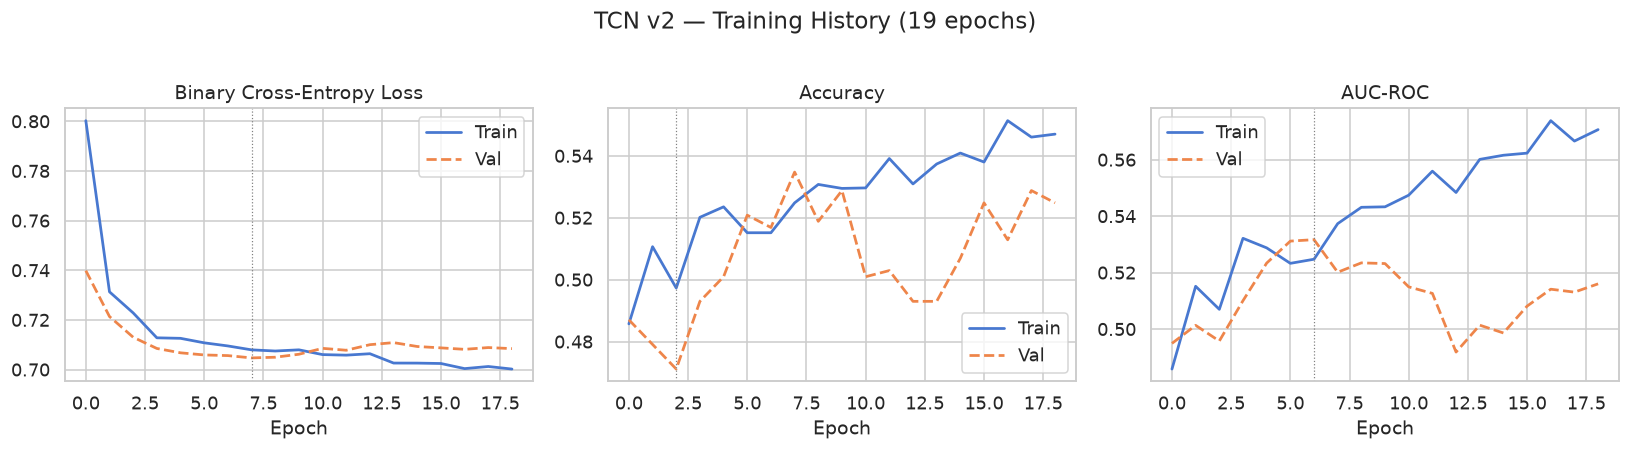

Best epoch: 7  |  val_auc=0.5317  |  val_loss=0.7057
Train–val AUC gap at best epoch: -0.0069


In [8]:
# ── Training curves ───────────────────────────────────────────────────────
hist = pd.DataFrame(history.history)
epochs_ran = len(hist)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (train_col, val_col, title) in zip(axes, [
    ("loss",     "val_loss",     "Binary Cross-Entropy Loss"),
    ("accuracy", "val_accuracy", "Accuracy"),
    ("auc",      "val_auc",      "AUC-ROC"),
]):
    ax.plot(hist[train_col], label="Train", linewidth=1.8)
    ax.plot(hist[val_col],   label="Val",   linewidth=1.8, linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.axvline(hist[val_col].idxmax() if "auc" in val_col else hist[val_col].idxmin(),
               color="gray", linewidth=0.8, linestyle=":")

fig.suptitle(f"TCN v2 — Training History ({epochs_ran} epochs)", y=1.02)
plt.tight_layout()
plt.show()

best_epoch = hist["val_auc"].idxmax()
gap = hist["auc"][best_epoch] - hist["val_auc"][best_epoch]
print(
    f"Best epoch: {best_epoch + 1}  |  val_auc={hist['val_auc'][best_epoch]:.4f}  "
    f"|  val_loss={hist['val_loss'][best_epoch]:.4f}"
)
print(f"Train–val AUC gap at best epoch: {gap:.4f}")


## 5. Evaluation

**Threshold tuning:** chosen on validation (max F1), applied to test unchanged.

**Primary metrics:** AUC-ROC, F1 at tuned threshold  
**Diagnostic:** prediction std should be >> 0.02 on both splits


In [9]:
def tune_threshold(y_true, y_prob):
    best_t, best_f1 = 0.5, 0.0
    for t in np.linspace(0.35, 0.65, 61):
        pred = (y_prob >= t).astype(int)
        f1 = f1_score(y_true, pred, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, float(t)
    return best_t, best_f1


def evaluate_split(model, X, y_true, split_name: str, threshold: float = 0.5) -> dict:
    y_prob = model.predict(X, verbose=0).flatten()
    y_pred = (y_prob >= threshold).astype(int)

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_prob)

    print(f"\n{'='*55}")
    print(f"  {split_name.upper()} RESULTS  (n={len(y_true)}, threshold={threshold:.3f})")
    print(f"{'='*55}")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  F1-score : {f1:.4f}")
    print(f"  AUC-ROC  : {auc:.4f}")
    print(f"  Prob std : {y_prob.std():.4f}")
    print(f"\n{classification_report(y_true, y_pred, target_names=['DOWN (0)', 'UP (1)'], zero_division=0)}")

    return {
        "split": split_name,
        "accuracy": acc,
        "f1": f1,
        "auc": auc,
        "threshold": threshold,
        "prob_std": float(y_prob.std()),
        "y_prob": y_prob,
        "y_pred": y_pred,
        "y_true": y_true,
    }


val_prob_tune = model.predict(X_val, verbose=0).flatten()
OPTIMAL_THRESHOLD, val_best_f1 = tune_threshold(y_val, val_prob_tune)
print(f"Optimal threshold (val, max F1): {OPTIMAL_THRESHOLD:.3f}  (val F1 at tune={val_best_f1:.4f})")

val_results = evaluate_split(
    model, X_val, y_val, "Validation (2018–2019)", threshold=OPTIMAL_THRESHOLD
)
test_results = evaluate_split(
    model, X_test, y_test, "Test — COVID Stress (2020 Q1)", threshold=OPTIMAL_THRESHOLD
)


Optimal threshold (val, max F1): 0.480  (val F1 at tune=0.7190)

  VALIDATION (2018–2019) RESULTS  (n=503, threshold=0.480)
  Accuracy : 0.5805
  F1-score : 0.7190
  AUC-ROC  : 0.5272
  Prob std : 0.0210

              precision    recall  f1-score   support

    DOWN (0)       0.79      0.10      0.17       227
      UP (1)       0.57      0.98      0.72       276

    accuracy                           0.58       503
   macro avg       0.68      0.54      0.45       503
weighted avg       0.67      0.58      0.47       503


  TEST — COVID STRESS (2020 Q1) RESULTS  (n=63, threshold=0.480)
  Accuracy : 0.5397
  F1-score : 0.6234
  AUC-ROC  : 0.5741
  Prob std : 0.0815

              precision    recall  f1-score   support

    DOWN (0)       0.77      0.28      0.41        36
      UP (1)       0.48      0.89      0.62        27

    accuracy                           0.54        63
   macro avg       0.62      0.58      0.52        63
weighted avg       0.65      0.54      0.50      

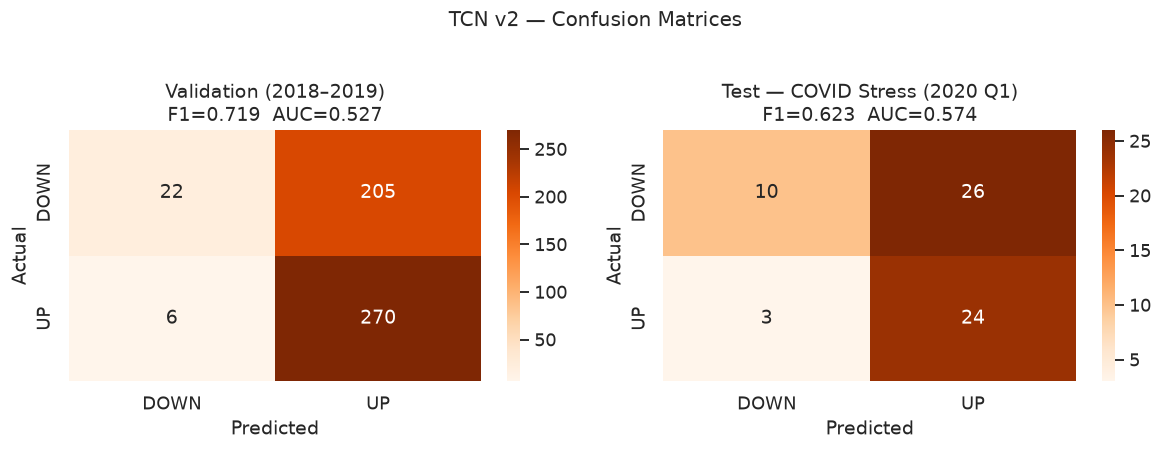

In [10]:
# ── Confusion matrices ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, res in zip(axes, [val_results, test_results]):
    cm = confusion_matrix(res["y_true"], res["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", ax=ax,
                xticklabels=["DOWN", "UP"], yticklabels=["DOWN", "UP"])
    ax.set_title(f"{res['split']}\nF1={res['f1']:.3f}  AUC={res['auc']:.3f}")
    ax.set_ylabel("Actual")
    ax.set_xlabel("Predicted")

fig.suptitle("TCN v2 — Confusion Matrices", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

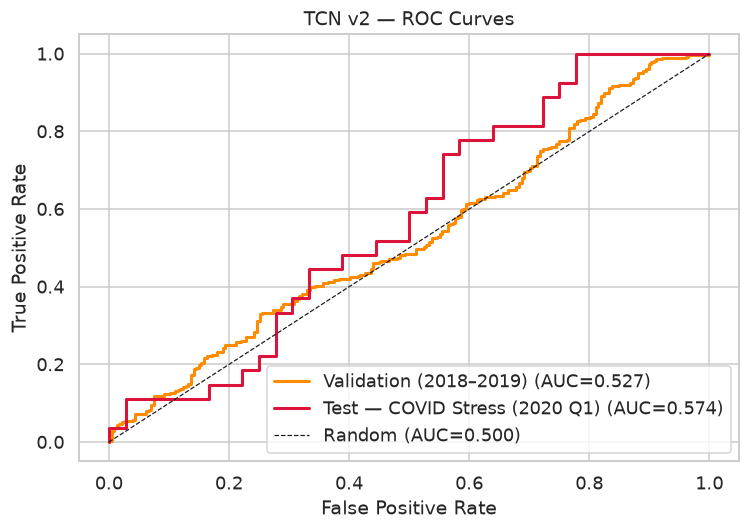

In [11]:
# ── ROC curves ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

for res, color in zip([val_results, test_results], ["darkorange", "crimson"]):
    fpr, tpr, _ = roc_curve(res["y_true"], res["y_prob"])
    ax.plot(fpr, tpr, label=f"{res['split']} (AUC={res['auc']:.3f})",
            color=color, linewidth=2)

ax.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Random (AUC=0.500)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("TCN v2 — ROC Curves")
ax.legend()
plt.tight_layout()
plt.show()

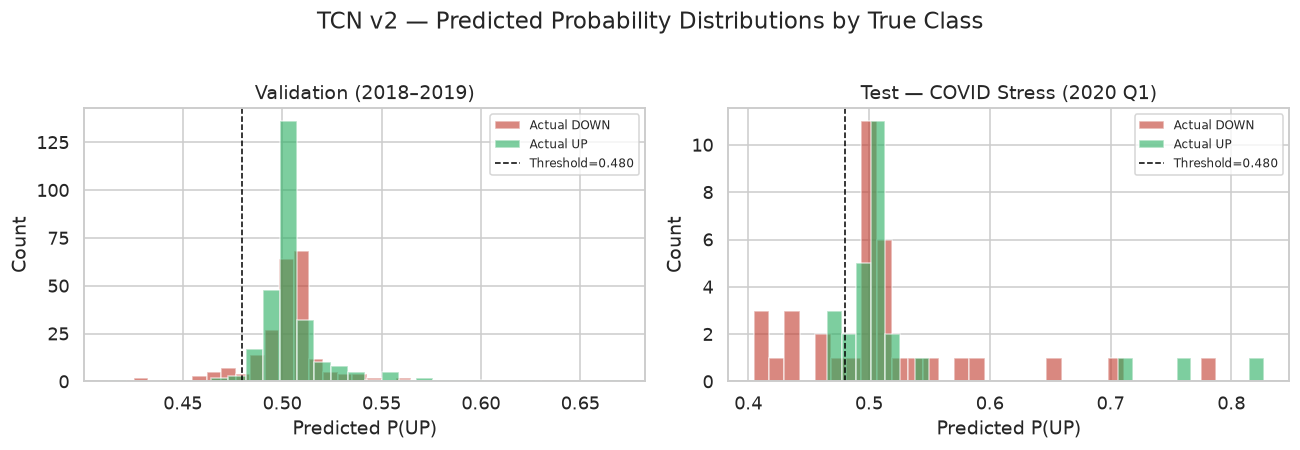

In [12]:
# ── Predicted probability distributions ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, res in zip(axes, [val_results, test_results]):
    for label, color, name in [(0, "#c0392b", "DOWN"), (1, "#27ae60", "UP")]:
        mask = res["y_true"] == label
        ax.hist(res["y_prob"][mask], bins=30, alpha=0.6,
                color=color, label=f"Actual {name}")
    ax.axvline(OPTIMAL_THRESHOLD, color="black", linewidth=1, linestyle="--", label=f"Threshold={OPTIMAL_THRESHOLD:.3f}")
    ax.set_xlabel("Predicted P(UP)")
    ax.set_ylabel("Count")
    ax.set_title(f"{res['split']}")
    ax.legend(fontsize=8)

fig.suptitle("TCN v2 — Predicted Probability Distributions by True Class", y=1.02)
plt.tight_layout()
plt.show()

## 6. Baseline Comparisons

Same baselines as the GRU notebook — ensures direct comparability.

| Baseline | Description |
|----------|-------------|
| Always UP | Predicts 1 (up) for every sample |
| Always DOWN | Predicts 0 (down) for every sample |
| Last direction | Predicts the direction of the most recent log_return in the lookback window |

In [13]:
def baseline_metrics(y_true, y_pred, name: str) -> dict:
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "F1": round(f1_score(y_true, y_pred, zero_division=0), 4),
    }


rows = []
for split_name, X, y in [("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    last_return = X[:, -1, 0]
    last_dir = (last_return > 0).astype(int)

    tcn_pred = (model.predict(X, verbose=0).flatten() >= OPTIMAL_THRESHOLD).astype(int)

    for row in [
        baseline_metrics(y, np.ones_like(y, dtype=int), f"[{split_name}] Always UP"),
        baseline_metrics(y, np.zeros_like(y, dtype=int), f"[{split_name}] Always DOWN"),
        baseline_metrics(y, last_dir, f"[{split_name}] Last Direction"),
        {
            "Model": f"[{split_name}] TCN v2 (ours)",
            "Accuracy": round(accuracy_score(y, tcn_pred), 4),
            "F1": round(f1_score(y, tcn_pred, zero_division=0), 4),
        },
    ]:
        rows.append(row)

baseline_df = pd.DataFrame(rows)
print(f"\nBaseline comparison (threshold={OPTIMAL_THRESHOLD:.3f}):")
display(baseline_df.set_index("Model"))



Baseline comparison (threshold=0.480):


,Accuracy,F1
Model,,
[Validation] Always UP,0.5487,0.7086
[Validation] Always DOWN,0.4513,0.0000
[Validation] Last Direction,0.5109,0.5428
[Validation] TCN v2 (ours),0.5805,0.7190
[Test] Always UP,0.4286,0.6000
[Test] Always DOWN,0.5714,0.0000
[Test] Last Direction,0.3968,0.2963
[Test] TCN v2 (ours),0.5397,0.6234


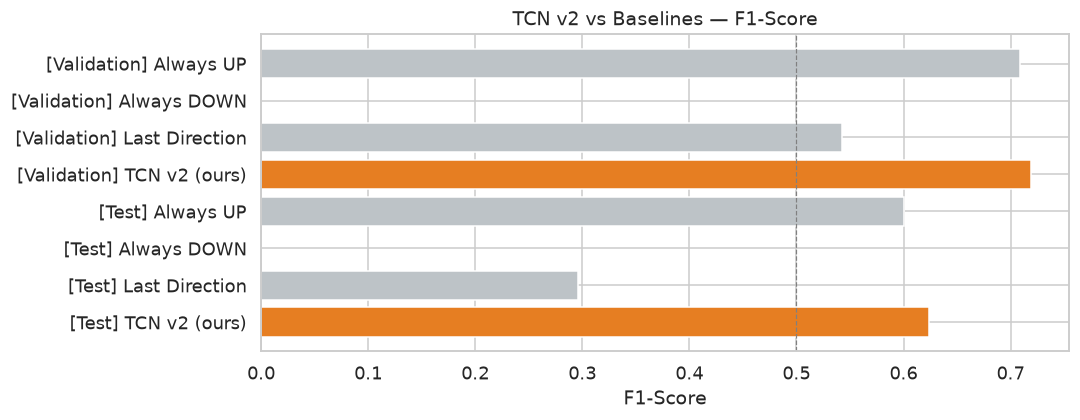

In [14]:
# ── Bar chart: F1 comparison ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
colors_bar = [
    "#e67e22" if "TCN" in m else "#bdc3c7"
    for m in baseline_df["Model"]
]
ax.barh(baseline_df["Model"], baseline_df["F1"], color=colors_bar, edgecolor="white")
ax.axvline(0.5, color="gray", linewidth=0.8, linestyle="--")
ax.set_xlabel("F1-Score")
ax.set_title("TCN v2 vs Baselines — F1-Score")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 7. Save Model & Results

In [15]:
# ── Save final model ──────────────────────────────────────────────────────
final_path = MODELS_DIR / "tcn_final.keras"
model.save(final_path)
print(f"Model saved: {final_path}")

preds = {
    "model_version": "tcn_v2",
    "optimal_threshold": OPTIMAL_THRESHOLD,
    "val_prob": val_results["y_prob"].tolist(),
    "val_pred": val_results["y_pred"].tolist(),
    "val_true": val_results["y_true"].tolist(),
    "test_prob": test_results["y_prob"].tolist(),
    "test_pred": test_results["y_pred"].tolist(),
    "test_true": test_results["y_true"].tolist(),
    "metrics": {
        "val": {
            "accuracy": val_results["accuracy"],
            "f1": val_results["f1"],
            "auc": val_results["auc"],
            "prob_std": val_results["prob_std"],
        },
        "test": {
            "accuracy": test_results["accuracy"],
            "f1": test_results["f1"],
            "auc": test_results["auc"],
            "prob_std": test_results["prob_std"],
        },
    },
}
preds_path = MODELS_DIR / "tcn_predictions.json"
with open(preds_path, "w") as f:
    json.dump(preds, f, indent=2)
print(f"Predictions saved: {preds_path}")

summary = pd.DataFrame([
    {"Split": "Validation (2018–2019)", **preds["metrics"]["val"]},
    {"Split": "Test — COVID Stress (2020 Q1)", **preds["metrics"]["test"]},
])
print(f"\n── TCN v2 Final Results (threshold={OPTIMAL_THRESHOLD:.3f}) ──")
display(summary.set_index("Split").round(4))


Model saved: /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/tcn_final.keras
Predictions saved: /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/tcn_predictions.json

── TCN v2 Final Results (threshold=0.480) ──


,accuracy,f1,auc,prob_std
Split,,,,
Validation (2018–2019),0.5805,0.7190,0.5272,0.0210
Test — COVID Stress (2020 Q1),0.5397,0.6234,0.5741,0.0815


---

## Summary

This notebook (v2) trains a **3-block TCN** with last-timestep readout on AAPL next-day direction prediction.

**v2 fixes:** removed GlobalAveragePooling, simplified stack, AdamW + light dropout, prior bias init, validation-tuned threshold.

**Key artifacts:**
- `data/models/tcn_best.keras` — best checkpoint (by val AUC)
- `data/models/tcn_final.keras` — final model
- `data/models/tcn_predictions.json` — probabilities, metrics, and optimal threshold
